### Low-Cost Gas Sensor Calibration Using Polynomial Regression

#### The practical problem
Low-cost electronic gas sensors are used in:

- IoT air-quality monitors
- Smart homes
- Industrial safety systems
- Environmental monitoring devices
- Embedded monitoring systems

However, sensor readings may not perfectly match the actual gas concentration.

This project will investigate whether Polynomial Regression can correct the readings of a low-cost gas sensor using measurements from a more accurate reference analyzer.

In [198]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [199]:
dataset = pd.read_excel('AirQualityUCI.xlsx')
dataset.head(5)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


##### The PT08.S1(CO) column is the response of a tin oxide sensor targeting CO, while CO(GT) column represents the reference analyzer's CO concentration.

##### This project will use only these two columns.

In [200]:
df = dataset[['PT08.S1(CO)', 'CO(GT)']]
df.head(5)

,PT08.S1(CO),CO(GT)
0,1360.00,2.6
1,1292.25,2.0
2,1402.00,2.2
3,1375.50,2.2
4,1272.25,1.6


In [201]:
df.shape

(9357, 2)

In [202]:
df.isnull().sum()

PT08.S1(CO)    0
CO(GT)         0
dtype: int64

In [203]:
df.dtypes

PT08.S1(CO)    float64
CO(GT)         float64
dtype: object

In [204]:
# The dataset uses -200 to represent missing measurements, so replace the missing values (-200) with mean
df['PT08.S1(CO)'] = df['PT08.S1(CO)'].replace(-200, df['PT08.S1(CO)'].mean())

In [205]:
# The dataset uses -200 to represent missing measurements, so replace the missing values (-200) with mean
df['CO(GT)'] = df['CO(GT)'].replace(-200, df['CO(GT)'].mean())

In [206]:
# The dataset uses -200 to represent missing measurements, 
# check whether this missing value (-200) is still present or not
df[df['PT08.S1(CO)'] == -200].value_counts

<bound method DataFrame.value_counts of Empty DataFrame
Columns: [PT08.S1(CO), CO(GT)]
Index: []>

In [207]:
# The dataset uses -200 to represent missing measurements, 
# check whether this missing value (-200) is still present or not
df[df['CO(GT)'] == -200].value_counts

<bound method DataFrame.value_counts of Empty DataFrame
Columns: [PT08.S1(CO), CO(GT)]
Index: []>

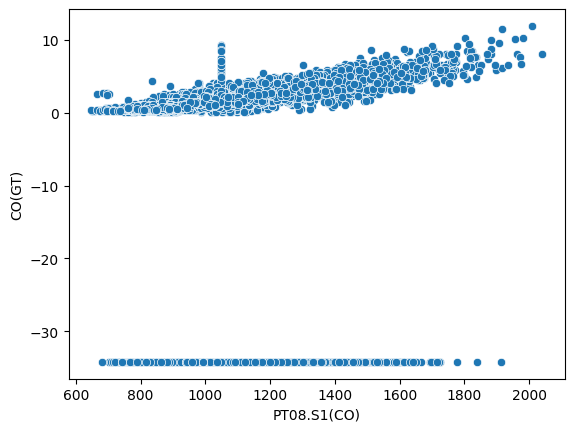

In [208]:
# Check the relationship between these two features using scatterplot
sns.scatterplot(x='PT08.S1(CO)', y='CO(GT)', data=df)
plt.show()

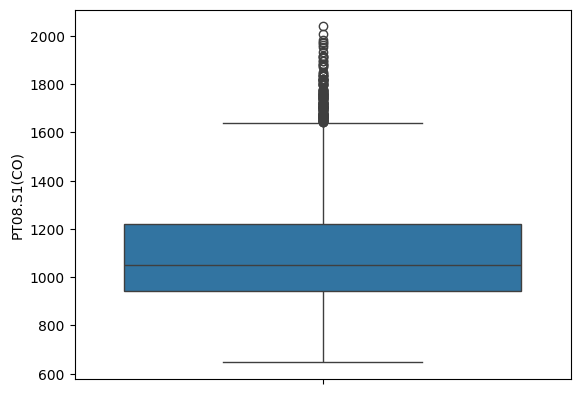

In [209]:
# plot boxplot to identify outliers
sns.boxplot(data=df['PT08.S1(CO)'])
plt.show()

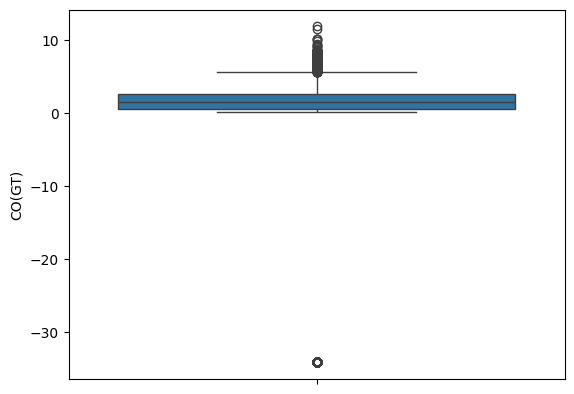

In [210]:
# plot boxplot to identify outliers
sns.boxplot(data=df['CO(GT)'])
plt.show()

##### Remove outliers from 'PT08.S1(CO)' column using IQR method

In [211]:
# Remove outliers from 'PT08.S1(CO)' column using IQR method
Q1 = df['PT08.S1(CO)'].quantile(0.25)
Q3 = df['PT08.S1(CO)'].quantile(0.75)
IQR = Q3-Q1
IQR

np.float64(280.0)

In [212]:
min_range = Q1 - (1.5*IQR)
max_range = Q3 + (1.5*IQR)
min_range, max_range

(np.float64(521.25), np.float64(1641.25))

In [213]:
df = df[(df['PT08.S1(CO)'] <= max_range) & (df['PT08.S1(CO)'] >= min_range)]

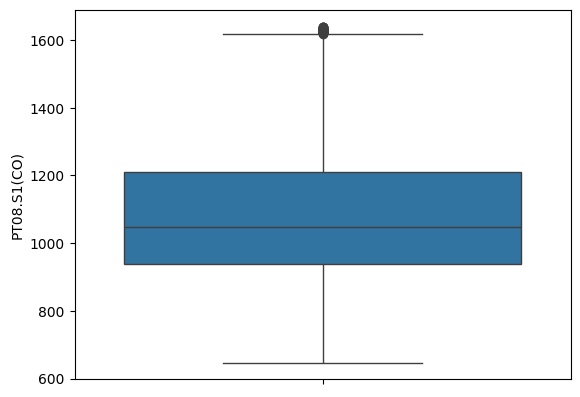

In [214]:
# Now plot boxplot to check if outliers still exist or not
sns.boxplot(data=df['PT08.S1(CO)'])
plt.show()

##### Remove outliers from 'CO(GT)' column using IQR method

In [215]:
# Remove outliers from 'CO(GT)' column using IQR method
Q_1 = df['CO(GT)'].quantile(0.25)
Q_3 = df['CO(GT)'].quantile(0.75)
IQ_R = Q_3-Q_1
IQ_R

np.float64(1.9)

In [216]:
Min_Range = Q_1 - (1.5*IQ_R)
Max_Range = Q_3 + (1.5*IQ_R)

Min_Range, Max_Range

(np.float64(-2.2499999999999996), np.float64(5.35))

In [217]:
df = df[(df['CO(GT)'] >= Min_Range) & (df['CO(GT)'] <= Max_Range)]

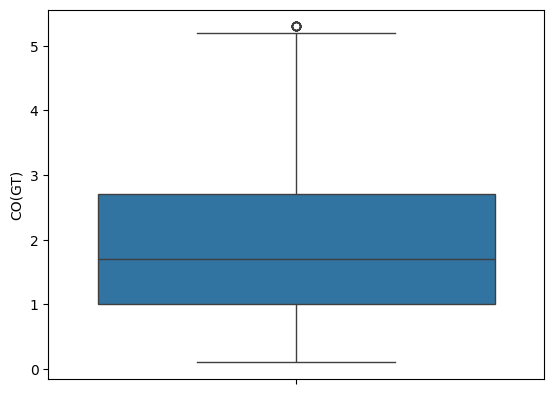

In [218]:
# Now plot boxplot to check if outliers still exist or not
sns.boxplot(data=df['CO(GT)'])
plt.show()

In [219]:
df.shape

(7362, 2)

In [220]:
df.dtypes

PT08.S1(CO)    float64
CO(GT)         float64
dtype: object

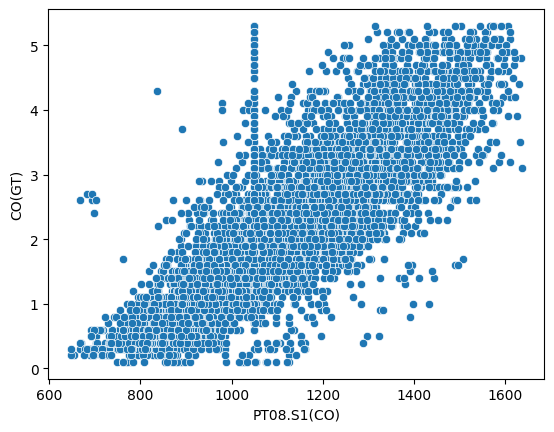

In [221]:
# Check the relationship between these two features using scatterplot
sns.scatterplot(x='PT08.S1(CO)', y='CO(GT)', data=df)
plt.show()

In [222]:
df.corr()

,PT08.S1(CO),CO(GT)
PT08.S1(CO),1.000000,0.834336
CO(GT),0.834336,1.000000


##### Create Independent and Dependent Variables

In [223]:
x = df[['PT08.S1(CO)']]
y = df['CO(GT)']

##### Convert these input feature/independent variable into polynomial feature

In [224]:
from sklearn.preprocessing import PolynomialFeatures

In [268]:
pf = PolynomialFeatures(degree=3)

In [269]:
pf.fit(x)
x1 = pf.transform(x)

##### Split the dataset into training and testing sets

In [270]:
from sklearn.model_selection import train_test_split

In [271]:
x_train, x_test, y_train, y_test = train_test_split(x1,y, test_size=0.2, random_state=45)

##### Initialize and Train Polynomial Regression

In [272]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

In [273]:
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0., 0., 0.,-0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.572
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[5.89e+10,3.18e+06,2.04e+02,0.00e+00]"


In [274]:
lr.score(x_test, y_test)

0.7127545845666581

In [275]:
y_pred = lr.predict(x1)

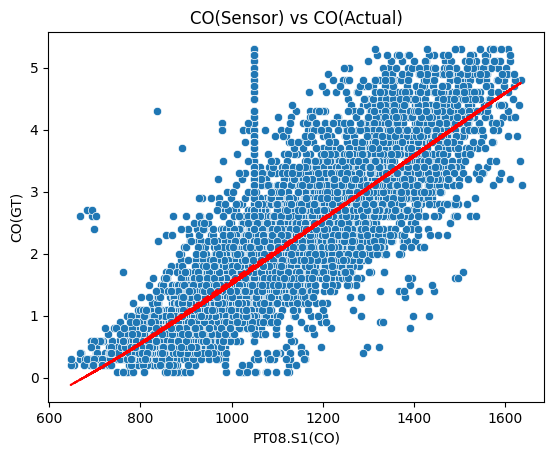

In [276]:
sns.scatterplot(x=df['PT08.S1(CO)'], y=df['CO(GT)'], data=df)
plt.plot(df['PT08.S1(CO)'], y_pred, '--', color='red', label='Prediction Line')
plt.title('CO(Sensor) vs CO(Actual)')
plt.xlabel('PT08.S1(CO)')
plt.ylabel('CO(GT)')
plt.show()

In [277]:
# Coefficients of the polynomial regression model
lr.coef_

array([ 0.00000000e+00,  3.72555375e-09,  4.20229632e-06, -1.12146790e-09])

In [278]:
# Intercept of the polynomial regression model
lr.intercept_

np.float64(-1.5718774733406529)